# Rule-Based Model
Build an initial clustering model using fixed rules based in the RFM framework.

# Import and Inspect Data

In [23]:
import pandas as pd

In [24]:
df = pd.read_excel('../data/Online Retail.xlsx')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [25]:
print(df['InvoiceNo'].value_counts(normalize=True) * 100)

InvoiceNo
573585     0.205570
581219     0.138215
581492     0.134893
580729     0.133048
558475     0.130096
             ...   
581487     0.000185
581491     0.000185
C581499    0.000185
581566     0.000185
C581568    0.000185
Name: proportion, Length: 25900, dtype: float64


In [26]:
print(df['StockCode'].value_counts(normalize=True) * 100)

StockCode
85123A    0.426824
22423     0.406526
85099B    0.398406
47566     0.318688
20725     0.302449
            ...   
23609     0.000185
85179a    0.000185
23617     0.000185
90214U    0.000185
47591b    0.000185
Name: proportion, Length: 4070, dtype: float64


In [27]:
print(df['Description'].value_counts(normalize=True) * 100)

Description
WHITE HANGING HEART T-LIGHT HOLDER    0.438334
REGENCY CAKESTAND 3 TIER              0.407064
JUMBO BAG RED RETROSPOT               0.399478
PARTY BUNTING                         0.319546
LUNCH BAG RED RETROSPOT               0.303078
                                        ...   
LETTER "U" BLING KEY RING             0.000185
wet                                   0.000185
wet boxes                             0.000185
????damages????                       0.000185
lost                                  0.000185
Name: proportion, Length: 4223, dtype: float64


In [28]:
print(df['Country'].value_counts(normalize=True) * 100)

Country
United Kingdom          91.431956
Germany                  1.752139
France                   1.579047
EIRE                     1.512431
Spain                    0.467422
Netherlands              0.437527
Belgium                  0.381798
Switzerland              0.369435
Portugal                 0.280305
Australia                0.232327
Norway                   0.200403
Italy                    0.148180
Channel Islands          0.139876
Finland                  0.128250
Cyprus                   0.114779
Sweden                   0.085254
Unspecified              0.082302
Austria                  0.073998
Denmark                  0.071783
Japan                    0.066063
Poland                   0.062926
Israel                   0.054806
USA                      0.053699
Hong Kong                0.053145
Singapore                0.042258
Iceland                  0.033585
Canada                   0.027864
Greece                   0.026942
Malta                    0.023436
United

In [29]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


# Clean Data

In [30]:
# Remove invalid invoices
df = df[((df['InvoiceNo'].str[0] == 'C') == False) & ((df['InvoiceNo'].str[0] == 'A') == False)]

print(len(df))
display(df)

532618


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [31]:
# Remove quantity and price less than or equal to zero
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print(len(df))
display(df)

530103


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [32]:
# Remove null customers
df = df[df['CustomerID'].notnull()]

print(len(df))
display(df)

397884


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [33]:
# Cast InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(len(df))
print(df.info())
display(df)

397884
<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[us]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      397884 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 27.3+ MB
None


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


# Create Variables

## Recency

In [34]:
# Get the last invoice date to use as reference date
reference_date = df['InvoiceDate'].max()

print(reference_date)

df_recency = (reference_date - df.groupby('CustomerID')['InvoiceDate'].max()).dt.days.reset_index()
df_recency.columns = ['CustomerID', 'Recency']
df_recency['CustomerID'] = df_recency['CustomerID'].astype(int)

print(len(df_recency))
display(df_recency)

2011-12-09 12:50:00


4338


,CustomerID,Recency
0,12346,325
1,12347,1
2,12348,74
3,12349,18
4,12350,309
...,...,...
4333,18280,277
4334,18281,180
4335,18282,7
4336,18283,3


## Frequency

In [40]:
purchase_dates = (
    df[['CustomerID', 'InvoiceNo', 'InvoiceDate']]
    .drop_duplicates(subset=['CustomerID', 'InvoiceNo'])
    .sort_values(['CustomerID', 'InvoiceDate'])
    .copy()
)

purchase_dates['DaysBetweenPurchases'] = (
    purchase_dates.groupby('CustomerID')['InvoiceDate']
    .diff()
    .dt.total_seconds()
    .div(24 * 60 * 60)
)

df_frequency = (
    purchase_dates.groupby('CustomerID', as_index=False)['DaysBetweenPurchases']
    .mean()
    .rename(columns={'DaysBetweenPurchases': 'AvgDaysBetweenPurchases'})
)

df_frequency['AvgDaysBetweenPurchases'] = df_frequency['AvgDaysBetweenPurchases'].fillna(
    df_frequency['CustomerID'].map(df_recency.set_index('CustomerID')['Recency'])
)

df_frequency['CustomerID'] = (
    df_frequency['CustomerID'].astype(int)
)

display(df_frequency)

,CustomerID,AvgDaysBetweenPurchases
0,12346,325.000000
1,12347,60.839699
2,12348,94.250926
3,12349,18.000000
4,12350,309.000000
...,...,...
4333,18280,277.000000
4334,18281,180.000000
4335,18282,118.922222
4336,18283,22.260556


## Monetary - Total Spent (Quantity * Price)

In [41]:
df['TotalSpent'] = df['Quantity'] * df['UnitPrice']

df_monetary = (
    df.groupby('CustomerID', as_index=False)['TotalSpent']
    .sum()
)

print(len(df_monetary))
display(df_monetary)

4338


,CustomerID,TotalSpent
0,12346.0,77183.60
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40
...,...,...
4333,18280.0,180.60
4334,18281.0,80.82
4335,18282.0,178.05
4336,18283.0,2094.88


## Merge All Features

In [42]:
df_features = (
    df_recency.merge(df_frequency, on='CustomerID')
    .merge(df_monetary, on='CustomerID')
)

print(len(df_features))
display(df_features)

4338


,CustomerID,Recency,AvgDaysBetweenPurchases,TotalSpent
0,12346,325,325.000000,77183.60
1,12347,1,60.839699,4310.00
2,12348,74,94.250926,1797.24
3,12349,18,18.000000,1757.55
4,12350,309,309.000000,334.40
...,...,...,...,...
4333,18280,277,277.000000,180.60
4334,18281,180,180.000000,80.82
4335,18282,7,118.922222,178.05
4336,18283,3,22.260556,2094.88


# Create Rules and Segment Customers

In [43]:
df_features['R_Score'] = (
    pd.qcut(
        df_features['Recency'].rank(method='first'),
        q=5,
        labels=[5, 4, 3, 2, 1]
    ).astype(int)
)

df_features['F_Score'] = (
    pd.qcut(
        df_features['AvgDaysBetweenPurchases'].rank(method='first'),
        q=5,
        labels=[5, 4, 3, 2, 1]
    ).astype(int)
)

df_features['M_Score'] = (
    pd.qcut(
        df_features['TotalSpent'].rank(method='first'),
        q=5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
)

df_features['RFM_Score'] = (
    df_features['R_Score'].astype(str) + df_features['F_Score'].astype(str) + df_features['M_Score'].astype(str)
)

df_features[['CustomerID', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']].head()

,CustomerID,R_Score,F_Score,M_Score,RFM_Score
0,12346,1,1,5,115
1,12347,5,3,5,535
2,12348,2,2,4,224
3,12349,4,5,4,454
4,12350,1,1,2,112


## Visualize Segments

In [56]:
def classify_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 4:
        return 'Loyal Customers'
    elif r == 5 and f >= 3:
        return 'New Customers'
    elif (r <= 2 and (f >= 3 or m >= 3)) or (r >= 4 and f <= 2 and m >= 3):
        return 'At Risk'
    else:
        return 'Low Value or Inactive'

df_features['Cluster_Classification'] = df_features.apply(classify_customer, axis=1)

In [57]:
summary = (
    df_features.groupby('Cluster_Classification')
    .agg(
        CustomersAmount=('CustomerID', 'nunique'),
        MedianRecency=('Recency', 'median'),
        MedianFrequency=('AvgDaysBetweenPurchases', 'median'),
        MedianTotalSpent=('TotalSpent', 'median'),
        TotalSpent=('TotalSpent', 'sum')
    )
    .sort_values('TotalSpent', ascending=False)
)

summary['PctCustomers'] = (
    summary['CustomersAmount'] / summary['CustomersAmount'].sum() * 100
)

summary

,CustomersAmount,MedianRecency,MedianFrequency,MedianTotalSpent,TotalSpent,PctCustomers
Cluster_Classification,,,,,,
Champions,679,8.0,27.783974,3198.250,5090523.870,15.652374
At Risk,1160,103.0,82.941927,816.365,1693161.303,26.740433
Low Value or Inactive,1626,84.0,144.272569,330.070,1049323.620,37.482711
Loyal Customers,731,29.0,28.000000,430.480,784209.471,16.851083
New Customers,142,6.0,62.056424,1618.020,294189.640,3.273398


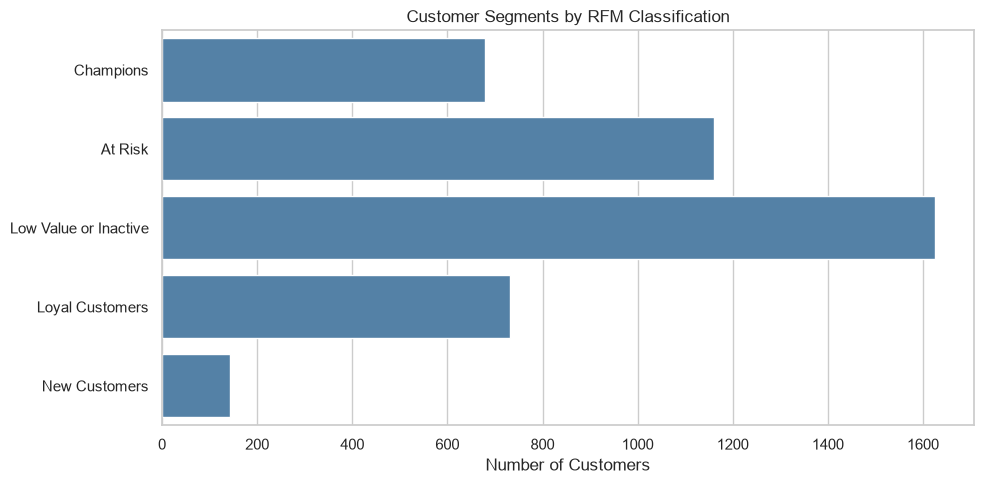

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

order = summary.index

plt.figure(figsize=(10, 5))
sns.countplot(data=df_features, y='Cluster_Classification', order=order, color='steelblue')
plt.title('Customer Segments by RFM Classification')
plt.xlabel('Number of Customers')
plt.ylabel('')
plt.tight_layout()
plt.show()

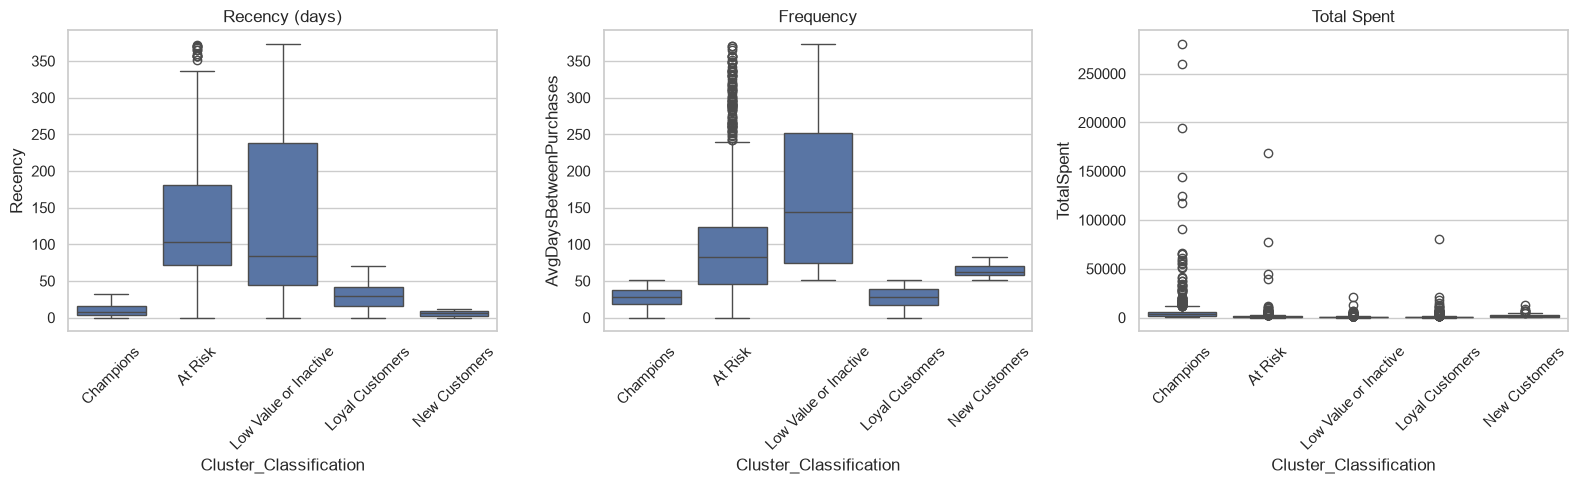

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metrica, title in zip(
    axes,
    ['Recency', 'AvgDaysBetweenPurchases', 'TotalSpent'],
    ['Recency (days)', 'Frequency', 'Total Spent']
):
    sns.boxplot(
        data=df_features,
        x='Cluster_Classification',
        y=metrica,
        order=order,
        ax=ax
    )
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Conclusions

Based on the above rules, we can see the following customer profiles:
- **Champions**: customers that spend a lot, buy often and bought recently. Those customers must be protected at all costs.
- **Loyal Customers**: customers that don't spend a lot, but buy often and bought recently. Those customers must be also valued by the company.
- **At Risk**: customers that used to buy often but don't buy for a while now. The company must invest in those customers to not lose them.
- **New Customers**: customers that made their first purchase recently. The company must also invest in those to build a good relationship.
- **Low Value or Inactive**: customers that spent few with the company and buy rarely; or don't buy anymore. Those must be the customers that the company pays the least attention.
